In [1]:
from src.mesh_setup import generate_mesh
mesh = generate_mesh(1/128)

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000529316s, CPU 0s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.912185s, CPU 0.887531s)
Info    : 19240 nodes 38482 elements
Info    : Done generating mesh


In [3]:
from dolfinx.fem.petsc import LinearProblem
from src.problem_builder import setup_problem
a, L, bcs = setup_problem(mesh, "Lagrange", "Lagrange", 1, 1)
problem = LinearProblem(
a,
L,
bcs=bcs,
kind="nest",
petsc_options_prefix="cavity",
petsc_options= {
    "ksp_type": "preonly",
    "pc_type": "lu",
    "pc_factor_mat_solver_type": "mumps"
} 
)
problem.solve()
A = problem.A
A00 = A.getNestSubMatrix(0,0)
A01 = A.getNestSubMatrix(0,1)
A10 = A.getNestSubMatrix(1,0)
print(f"Matrix size:", A.getSize())
print(f"A00 size:", A00.getSize())
print(f"A01 size:", A01.getSize())

Info    : Done setting up problem
Matrix size: (57720, 57720)
A00 size: (38480, 38480)
A01 size: (38480, 19240)


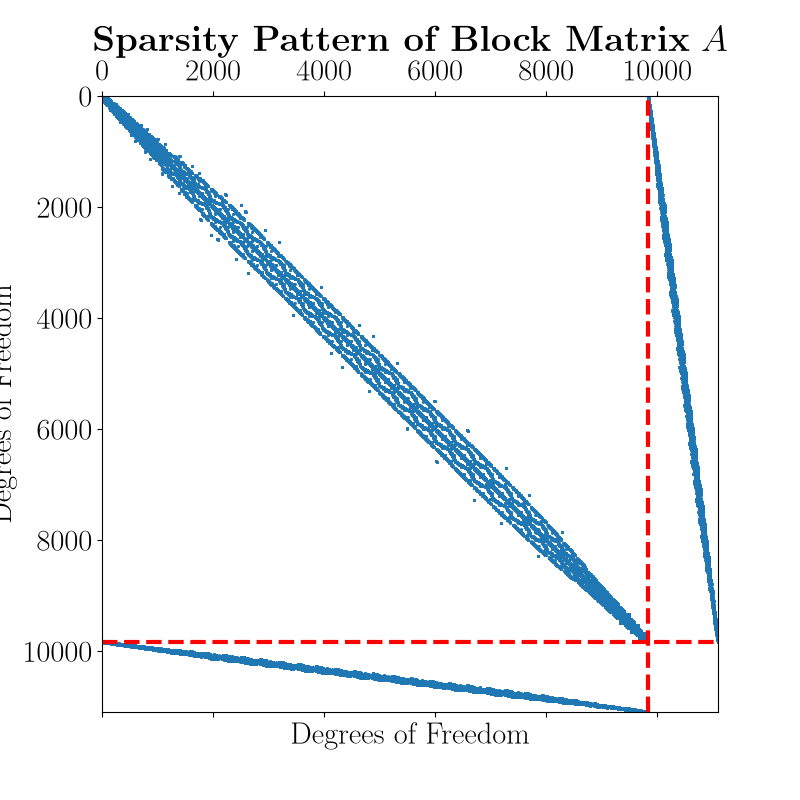

In [3]:
%matplotlib widget
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

# Assuming 'A' is your nested PETSc Mat (MatNest) from assemble_matrix_block

# 1. Convert nested matrix to a standard monolithic PETSc AIJ matrix
A_mono = A.convert("aij")
split_dof = A00.getSize()[0]

# 2. Extract CSR arrays
ai, aj, av = A_mono.getValuesCSR()
A_scipy = csr_matrix((av, aj, ai), shape=A_mono.getSizes()[0])

# 3. Plot sparsity pattern

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "font.size": 22,
})
plt.figure(figsize=(8, 8))
plt.spy(A_scipy, markersize=1, precision=1e-12)
plt.axvline(x=split_dof, color='red', linestyle='--', linewidth=3, label="Block Boundary")
plt.axhline(y=split_dof, color='red', linestyle='--', linewidth=3)

plt.title(r"\textbf{Sparsity Pattern of Block Matrix} $A$")
plt.xlabel("Degrees of Freedom")
plt.ylabel("Degrees of Freedom")

plt.savefig("/home/lukasl/Documents/vienna_uni/computational_analysis_seminar/comp_math_presentation/images/matrix_sparsity.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000213772s, CPU 0.000316s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00935972s, CPU 0.009631s)
Info    : 338 nodes 678 elements
Info    : Done generating mesh
Info    : Done setting up problem


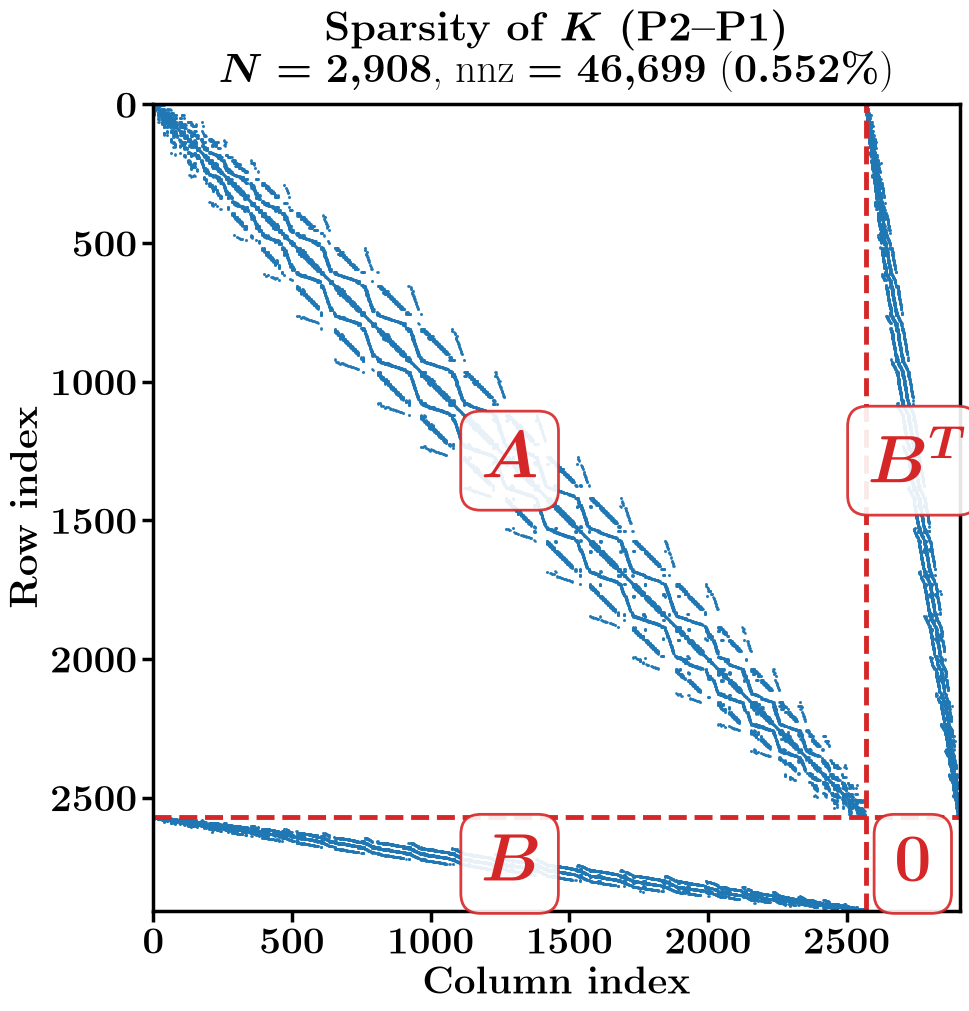

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from dolfinx import fem
from dolfinx.fem.petsc import assemble_matrix
from src.mesh_setup import generate_mesh
from src.problem_builder import setup_problem

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\boldmath",      # bold math: tick labels, block labels, N, nnz
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "font.size": 28,
    "axes.linewidth": 2.5,                    # thicker frame
    "xtick.major.width": 2.5, "ytick.major.width": 2.5,
    "xtick.major.size": 8,    "ytick.major.size": 8,
})

MESH_SIZE = 1/16
V_DEG, Q_DEG = 2, 1

mesh_data = generate_mesh(MESH_SIZE)
a, L, bcs = setup_problem(mesh_data, "Lagrange", "Lagrange", V_DEG, Q_DEG)

# Assemble only (no solve needed), then merge the blocks into one AIJ matrix
K = assemble_matrix(fem.form(a), bcs=bcs, kind="nest")
K.assemble()
n_u = K.getNestSubMatrix(0, 0).getSize()[0]          # velocity unknowns = block boundary
K_aij = K.convert("aij")
ai, aj, av = K_aij.getValuesCSR()
K_scipy = csr_matrix((av, aj, ai), shape=K_aij.getSize())
K_scipy.eliminate_zeros()                             # drop stored zeros (e.g. from BC rows)

N = K_scipy.shape[0]
nnz = K_scipy.nnz

fig, ax = plt.subplots(figsize=(10, 10), constrained_layout=True)
ax.spy(K_scipy, markersize=0.8, color="tab:blue")

# block boundaries
ax.axvline(n_u - 0.5, color="tab:red", linestyle="--", lw=3.5)
ax.axhline(n_u - 0.5, color="tab:red", linestyle="--", lw=3.5)

# block labels at the centre of each block
box = dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="tab:red", linewidth=2, alpha=0.9)
mid_u, mid_p = n_u / 2, (n_u + N) / 2
for (x, y, text) in [(mid_u, mid_u, r"$A$"), (mid_p, mid_u, r"$B^T$"),
                     (mid_u, mid_p, r"$B$"), (mid_p, mid_p, r"$0$")]:
    ax.text(x, y, text, ha="center", va="center", fontsize=48, color="tab:red", bbox=box)

ax.set_xlabel(r"\textbf{Column index}")
ax.set_ylabel(r"\textbf{Row index}")
ax.xaxis.set_label_position("bottom")
ax.xaxis.tick_bottom()
ax.set_title(rf"\textbf{{Sparsity of $K$ (P{V_DEG}--P{Q_DEG})}}" "\n"
             rf"$N = {N:,}$, nnz $= {nnz:,}$ (${100 * nnz / N**2:.3f}\%$)".replace(",", r"{,}"),
             fontsize=30, pad=16)

plt.savefig("/home/lukasl/Documents/vienna_uni/computational_analysis_seminar/comp_math_presentation/images/matrix_sparsity.png",
            dpi=300, bbox_inches="tight", transparent=True)
plt.show()